# **Machine Learning holidays project**

### **TASK 1: Linear Regression - House Price Prediction**

  PropertyID  Area_sqft  Bedrooms  Bathrooms  PropertyAge_years  \
0      H0001       1920         5          3                 30   
1      H0002       2153         4          2                 12   
2      H0003       1767         4          2                  5   
3      H0004       1527         6          4                 23   
4      H0005        899         2          1                  8   

   DistanceToCity_km  ParkingSpaces  Price_INR  
0               19.7              0   13776000  
1                5.3              1   15357000  
2               13.8              2   13312000  
3                1.7              2   12982000  
4                7.8              1    6886000  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PropertyID         500 non-null    object 
 1   Area_sqft          500 non-null    int64  
 2   Be

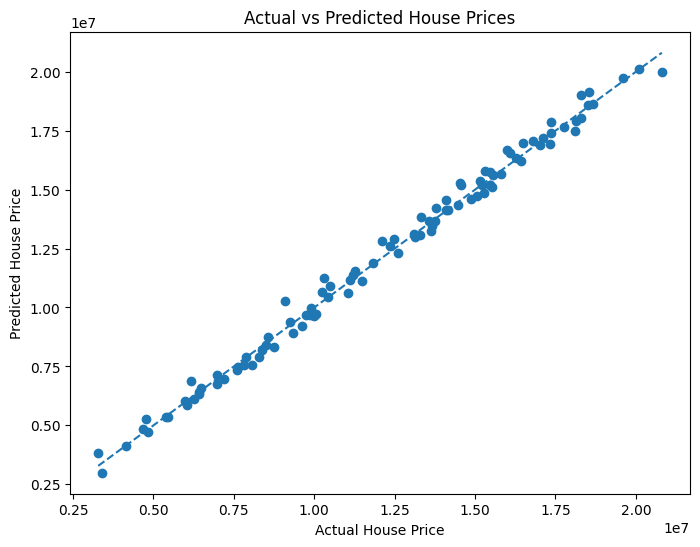

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

df=pd.read_excel("ML_Project_Linear_Regression_Housing_Data.xlsx")

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

x=df[['Area_sqft','Bedrooms','Bathrooms','PropertyAge_years','DistanceToCity_km','ParkingSpaces']]
y=df['Price_INR']

model=LinearRegression()

print("initialisation of model is completed")
print("starting to train the model")

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

model.fit(x_train,y_train)

print("model has trained successfully")

y_pred=model.predict(x_test)

prediction=pd.DataFrame({
    'Actual':y_test.values,
    'Predicted':y_pred,
    'error':y_test.values-y_pred
})

print(prediction)

print("predicted value",y_pred)

mae=mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

mse=mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

rmse=root_mean_squared_error(y_test,y_pred)
print("Root Mean Squared Error:",rmse)

r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)
plt.figure(figsize=(8,6))

plt.scatter(y_test,y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    linestyle='--'
)

plt.show()

### **TASK 2: Logistic Regression - Student Pass/Fail Prediction**

In [ ]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

df=pd.read_excel("ML_Project_Classification_Student_Data.xlsx")

print(df.head())
print(df.info())
print(df.isnull().sum())

x=df[['GeneralMarks','InternalMarks','Attendance_pct','AssignmentMarks','StudyHoursPerDay']]

df['Result']=df['Result'].map({'Pass':1,'Fail':0})

y=df['Result']

model=LogisticRegression()

print("initialisation of model is completed")
print("starting to train the model")

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

model.fit(x_train,y_train)

print("model has trained successfully")

y_pred=model.predict(x_test)

prediction=pd.DataFrame({
    'Actual':y_test.values,
    'Predicted':y_pred
})

print(prediction)

print("predicted value",y_pred)

cm=confusion_matrix(y_test,y_pred,labels=[0,1])

print("Confusion Matrix:")
print(cm)

tn,fp,fn,tp=cm.ravel()

print("True negative",tn)
print("False positive",fp)
print("False negative",fn)
print("True positive",tp)

accuracy=accuracy_score(y_test,y_pred)

precision=precision_score(
    y_test,y_pred,pos_label=1,zero_division=0
)

recall=recall_score(
    y_test,y_pred,pos_label=1,zero_division=0
)

f1=f1_score(
    y_test,y_pred,pos_label=1,zero_division=0
)

print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

print("Classification Report:")

print(classification_report(
    y_test,y_pred,
    labels=[0,1],
    target_names=['Fail','Pass'],
    zero_division=0
))

new_student=pd.DataFrame({
    'GeneralMarks':[85],
    'InternalMarks':[55],
    'Attendance_pct':[90],
    'AssignmentMarks':[80],
    'StudyHoursPerDay':[5]
})

pred=model.predict(new_student)

print("Predicted result:",pred)

if pred[0]==1:
    print("Student is predicted to Pass")
else:
    print("Student is predicted to Fail")

  StudentID  GeneralMarks  InternalMarks  Attendance_pct  AssignmentMarks  \
0     S0001            69             40              62               57   
1     S0002            53             32              99               59   
2     S0003            53             42              49               49   
3     S0004            61             50              97               65   
4     S0005            66             39              53               55   

   StudyHoursPerDay Result  
0                 6   Pass  
1                 5   Pass  
2                 4   Fail  
3                 4   Pass  
4                 1   Pass  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   StudentID         600 non-null    object
 1   GeneralMarks      600 non-null    int64 
 2   InternalMarks     600 non-null    int64 
 3   Attendance_pct    600 no

### **Comparison with RandomForest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model2=RandomForestClassifier(
    max_depth=3,
    n_estimators=100,
    random_state=42
)

print("initialisation of Random Forest model is completed")
print("starting to train the model")

model2.fit(x_train,y_train)

print("model has trained successfully")

y_pred2=model2.predict(x_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test,y_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test,y_pred2))

print("Logistic Regression F1 Score:",
      f1_score(y_test,y_pred,zero_division=0))

print("Random Forest F1 Score:",
      f1_score(y_test,y_pred2,zero_division=0))

initialisation of Random Forest model is completed
starting to train the model
model has trained successfully
Logistic Regression Accuracy: 0.7916666666666666
Random Forest Accuracy: 0.75
Logistic Regression F1 Score: 0.8538011695906432
Random Forest F1 Score: 0.8387096774193549


### **TASK 3: Decision Tree Regression - Sales Prediction**

In [ ]:
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

df=pd.read_excel("ML_Project_Decision_Tree_Sales_Data.xlsx")

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

x=df[['AdvertisingSpend_INR','ProductPrice_INR','Discount_pct','Season']]

x=pd.get_dummies(x,columns=['Season'],dtype=int)

y=df['UnitsSold']

print(x.head())

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

model=DecisionTreeRegressor(max_depth=2,random_state=42)

print("initialisation of model is completed")
print("starting to train the model")

model.fit(x_train,y_train)

print("model has trained successfully")

y_pred=model.predict(x_test)

prediction=pd.DataFrame({
    'Actual':y_test.values,
    'Predicted':y_pred,
    'error':y_test.values-y_pred
})

print(prediction)

mae=mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

mse=mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

rmse=root_mean_squared_error(y_test,y_pred)
print("Root Mean Squared Error:",rmse)

r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)

  CampaignID  AdvertisingSpend_INR  ProductPrice_INR  Discount_pct  Season  \
0      C0001              15842.31               823            16  Medium   
1      C0002              23166.74               394            29     Low   
2      C0003              15913.62               863            16  Medium   
3      C0004              28274.50              1588            20  Medium   
4      C0005              20983.57               528             2     Low   

   UnitsSold  
0        747  
1        768  
2        735  
3        965  
4        913  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CampaignID            400 non-null    object 
 1   AdvertisingSpend_INR  400 non-null    float64
 2   ProductPrice_INR      400 non-null    int64  
 3   Discount_pct          400 non-null    int64  
 4   Season                400 

In [ ]:
depth_values=[2,3,5]

for depth in depth_values:

    model=DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(x_train,y_train)

    y_pred=model.predict(x_test)

    mae=mean_absolute_error(y_test,y_pred)

    rmse=root_mean_squared_error(y_test,y_pred)

    r2=r2_score(y_test,y_pred)

    print("Max Depth:",depth)
    print("MAE:",mae)
    print("RMSE:",rmse)
    print("R2 Score:",r2)

Max Depth: 2
MAE: 118.04041437640576
RMSE: 154.4390506137602
R2 Score: 0.7561825209444066
Max Depth: 3
MAE: 115.61301971079237
RMSE: 148.10745257512647
R2 Score: 0.7757644766471467
Max Depth: 5
MAE: 129.08942967542475
RMSE: 160.11340309089036
R2 Score: 0.7379368441661027
